# PlantVillage — Baseline CNN

This notebook establishes a baseline convolutional neural network (CNN) for classifying PlantVillage plant disease images.

The model is trained using the stratified training split created in the previous phase. The validation set is used during training, while the test set remains isolated for final evaluation.

### Objectives

- Build a reproducible image classification pipeline
- Train a CNN from scratch
- Establish a baseline performance benchmark
- Evaluate overall and per-class performance
- Analyze the effect of class imbalance
- Save the trained baseline model

This baseline will later be compared with transfer-learning approaches.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from tensorflow.keras import layers, models

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "plantvillage"
MODEL_DIR = PROJECT_ROOT / "models"

TRAIN_PATH = DATA_DIR / "train.csv"
VAL_PATH = DATA_DIR / "validation.csv"
TEST_PATH = DATA_DIR / "test.csv"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 15
RANDOM_SEED = 42

tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("TensorFlow version:", tf.__version__)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

TensorFlow version: 2.22.0-rc0
Image size: (128, 128)
Batch size: 32


In [3]:
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Training images:   {len(train_df):,}")
print(f"Validation images: {len(val_df):,}")
print(f"Test images:       {len(test_df):,}")

Training images:   38,012
Validation images: 8,146
Test images:       8,146


In [4]:
class_ids = sorted(train_df["class_id"].unique())

class_to_index = {
    class_id: index
    for index, class_id in enumerate(class_ids)
}

index_to_class = {
    index: class_id
    for class_id, index in class_to_index.items()
}

NUM_CLASSES = len(class_ids)

print("Number of classes:", NUM_CLASSES)

Number of classes: 38


In [5]:
for df in (train_df, val_df, test_df):
    df["label"] = df["class_id"].map(class_to_index)

if train_df["label"].isna().any():
    raise ValueError("Unknown class found in training data.")

if val_df["label"].isna().any():
    raise ValueError("Unknown class found in validation data.")

if test_df["label"].isna().any():
    raise ValueError("Unknown class found in test data.")

print("Labels successfully mapped.")

Labels successfully mapped.


In [6]:
def resolve_paths(df):
    paths = []

    for path in df["image_path"]:
        image_path = PROJECT_ROOT / path

        if not image_path.exists():
            raise FileNotFoundError(f"Image not found: {image_path}")

        paths.append(str(image_path))

    return paths


train_paths = resolve_paths(train_df)
val_paths = resolve_paths(val_df)
test_paths = resolve_paths(test_df)

print("All image paths resolved.")

All image paths resolved.


In [7]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


def create_dataset(paths, labels, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=RANDOM_SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE,
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [8]:
train_dataset = create_dataset(
    train_paths,
    train_df["label"].values,
    shuffle=True,
)

val_dataset = create_dataset(
    val_paths,
    val_df["label"].values,
)

test_dataset = create_dataset(
    test_paths,
    test_df["label"].values,
)

print("TensorFlow datasets created.")

TensorFlow datasets created.


In [9]:
images, labels = next(iter(train_dataset))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range:", images.numpy().min(), "to", images.numpy().max())

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Pixel range: 0.0 to 1.0


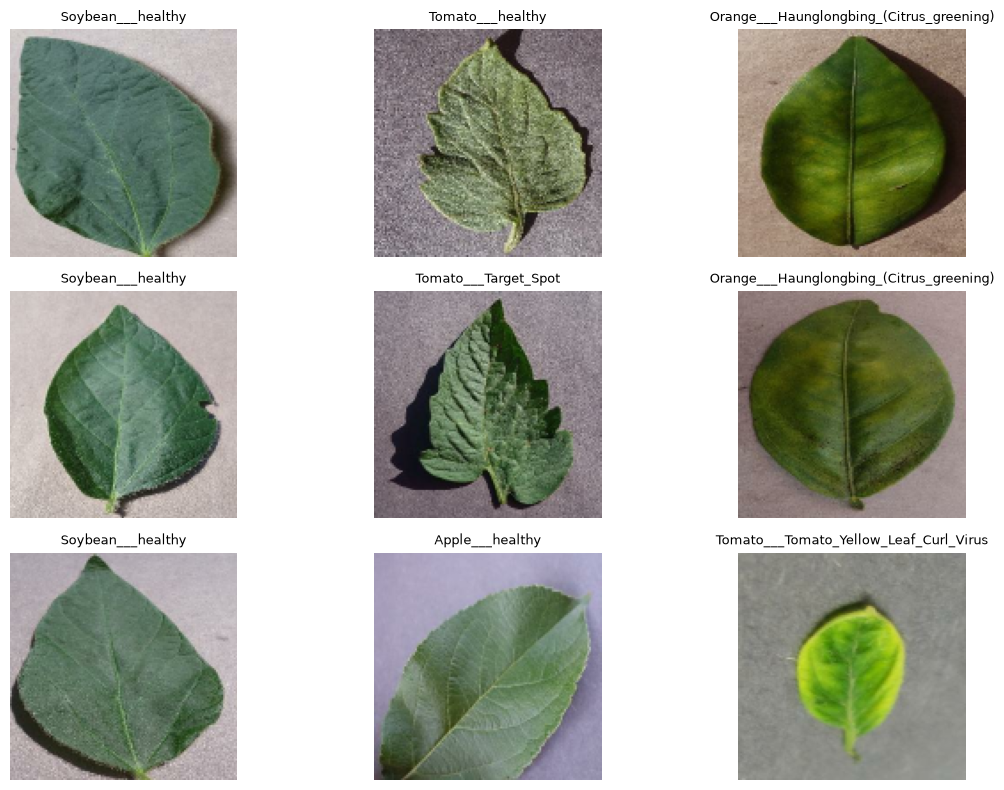

In [10]:
plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    image = images[i].numpy()
    label_index = int(labels[i].numpy())
    class_id = index_to_class[label_index]

    class_name = train_df.loc[
        train_df["class_id"] == class_id,
        "class_name"
    ].iloc[0]

    plt.imshow(image)
    plt.title(class_name, fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

## Baseline CNN Architecture

The baseline model uses three convolutional blocks followed by fully connected layers.

Each convolutional block contains:

- Convolution
- ReLU activation
- Max pooling

Dropout is included before the final classification layer to reduce overfitting.

The final layer contains 38 outputs, corresponding to the 38 PlantVillage disease classes.

In [11]:
model = models.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(NUM_CLASSES, activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,309,542 (12.62 MB)

 Trainable params: 3,309,542 (12.62 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [13]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
)

Epoch 1/15


/Users/devangvamja/Documents/Projects/agrivision-ai/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1188/1188 ━━━━━━━━━━━━━━━━━━━━ 115s 96ms/step - accuracy: 0.4515 - loss: 1.9886 - val_accuracy: 0.7161 - val_loss: 0.9597
Epoch 2/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 152s 128ms/step - accuracy: 0.6531 - loss: 1.1480 - val_accuracy: 0.8159 - val_loss: 0.6071
Epoch 3/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 147s 124ms/step - accuracy: 0.7306 - loss: 0.8710 - val_accuracy: 0.8481 - val_loss: 0.4893
Epoch 4/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 146s 123ms/step - accuracy: 0.7789 - loss: 0.6954 - val_accuracy: 0.8928 - val_loss: 0.3187
Epoch 5/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 151s 127ms/step - accuracy: 0.8104 - loss: 0.5840 - val_accuracy: 0.8860 - val_loss: 0.3525
Epoch 6/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 153s 128ms/step - accuracy: 0.8352 - loss: 0.5006 - val_accuracy: 0.9076 - val_loss: 0.2741
Epoch 7/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 150s 126ms/step - accuracy: 0.8519 - loss: 0.4470 - val_accuracy: 0.8952 - val_loss: 0.3087
Epoch 8/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 150s 126ms/step - accuracy: 0.86

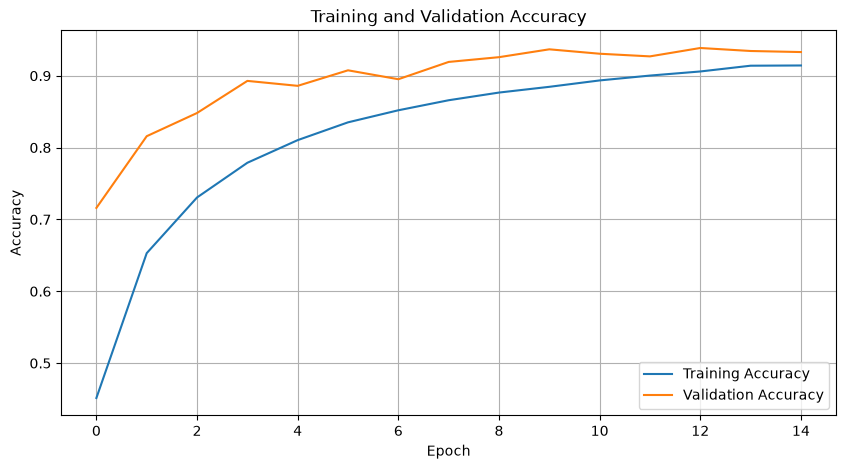

In [14]:
history_df = pd.DataFrame(history.history)

plt.figure(figsize=(10, 5))

plt.plot(history_df["accuracy"], label="Training Accuracy")
plt.plot(history_df["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

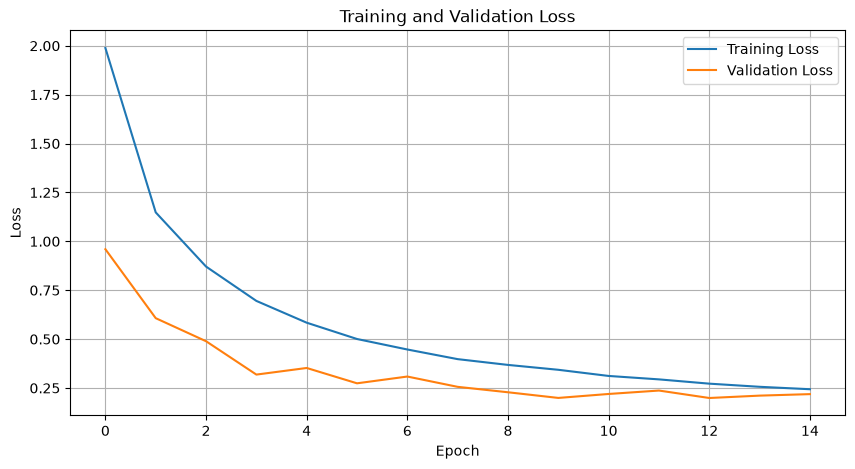

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(history_df["loss"], label="Training Loss")
plt.plot(history_df["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [16]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

255/255 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.9368 - loss: 0.2208
Test Loss:     0.2208
Test Accuracy: 0.9368


In [17]:
y_true = []
y_pred = []

for images_batch, labels_batch in test_dataset:
    predictions = model.predict(images_batch, verbose=0)

    y_true.extend(labels_batch.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions generated:", len(y_pred))

Predictions generated: 8146


In [18]:
target_names = [
    train_df.loc[
        train_df["class_id"] == index_to_class[i],
        "class_name"
    ].iloc[0]
    for i in range(NUM_CLASSES)
]

report = classification_report(
    y_true,
    y_pred,
    target_names=target_names,
    digits=4,
)

print(report)

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.9524    0.8511    0.8989        94
                                 Apple___Black_rot     0.9556    0.9247    0.9399        93
                          Apple___Cedar_apple_rust     0.9189    0.8293    0.8718        41
                                   Apple___healthy     0.8848    0.9636    0.9225       247
                               Blueberry___healthy     0.9610    0.9823    0.9716       226
          Cherry_(including_sour)___Powdery_mildew     0.9809    0.9747    0.9778       158
                 Cherry_(including_sour)___healthy     0.9328    0.9766    0.9542       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.8367    0.5325    0.6508        77
                       Corn_(maize)___Common_rust_     1.0000    0.9832    0.9915       179
               Corn_(maize)___Northern_Leaf_Blight     0.7600    0.9048    0.82

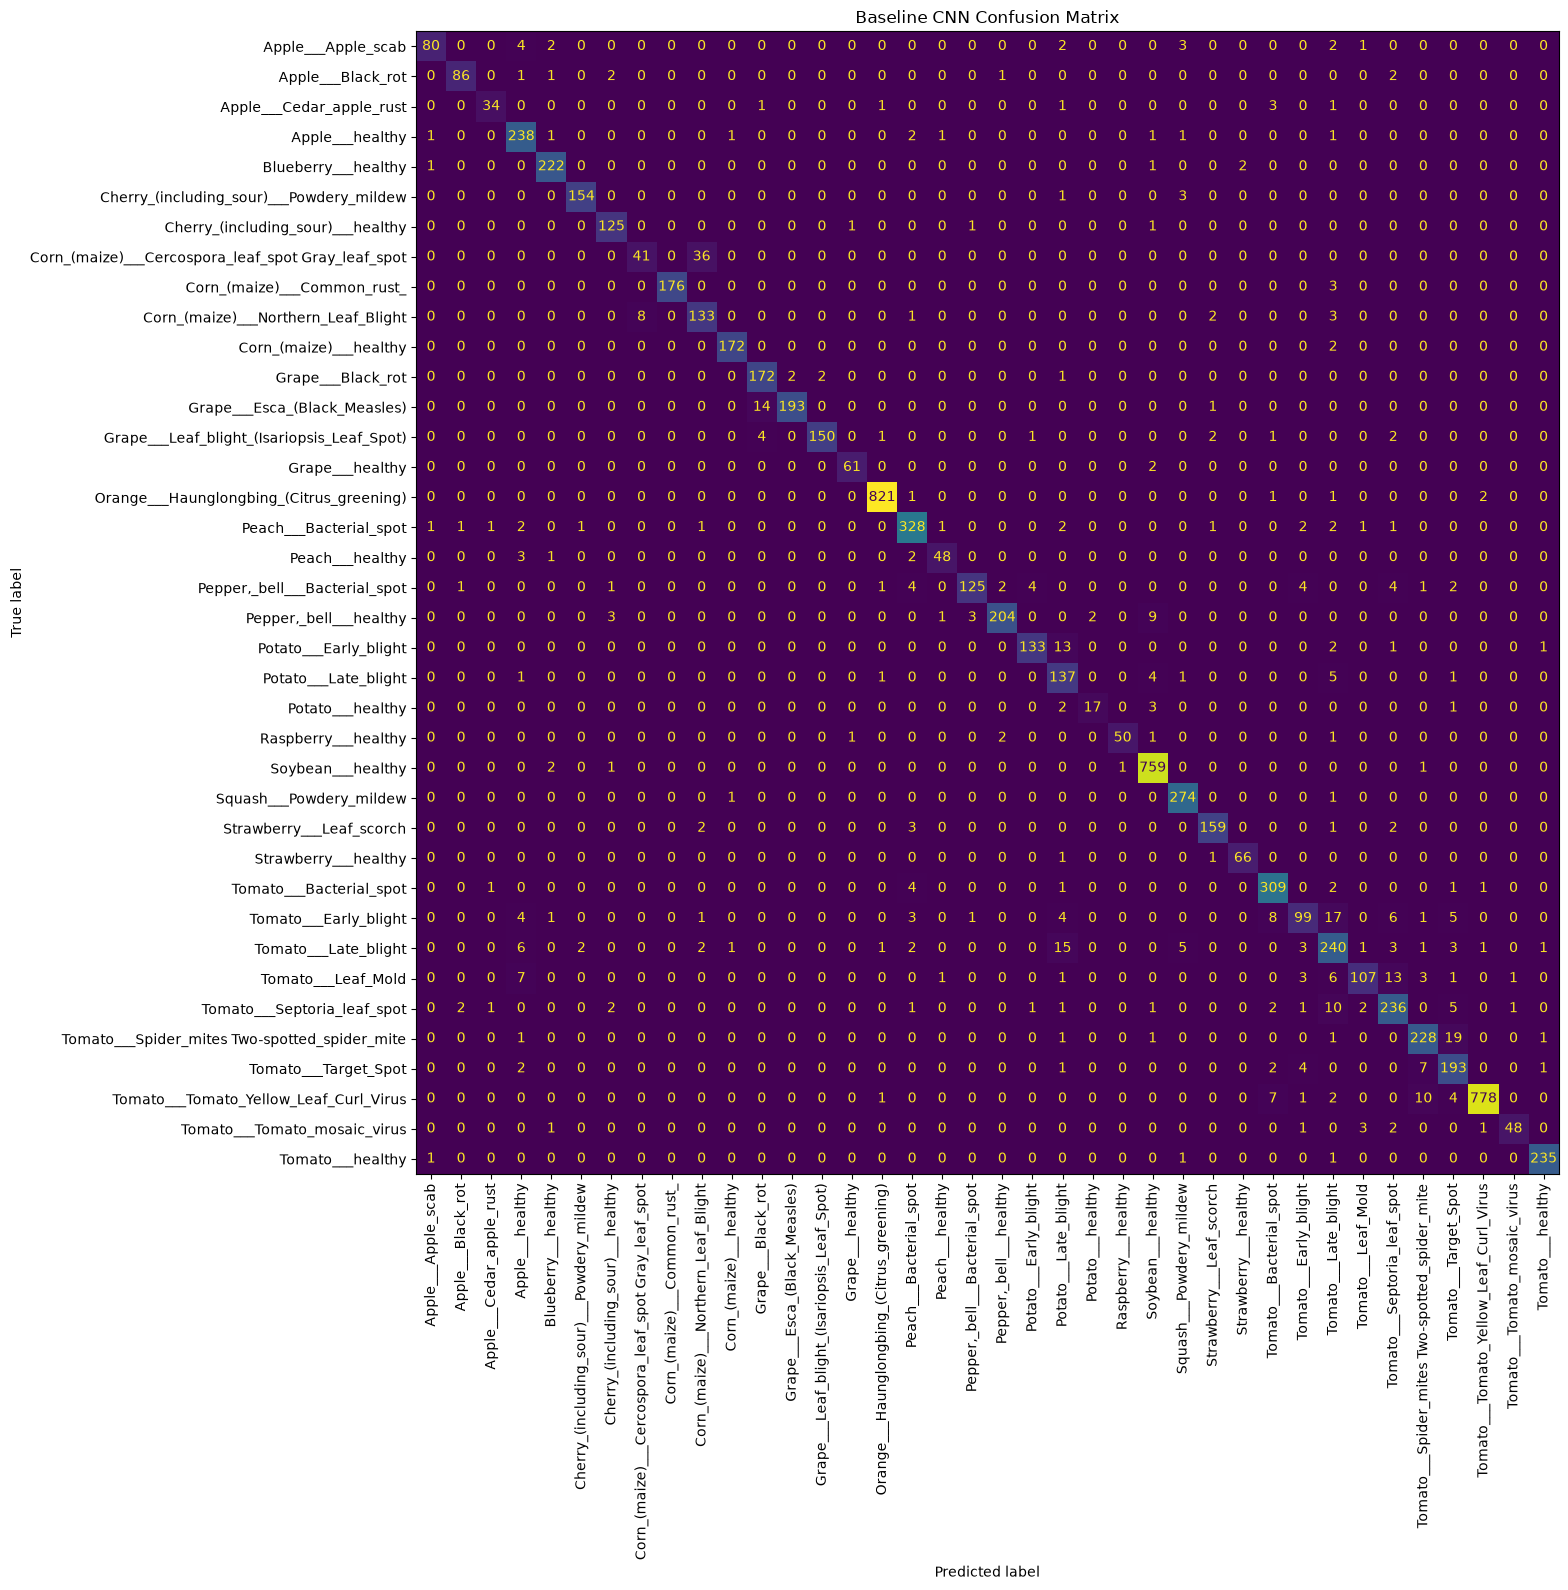

In [19]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(16, 16))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_names,
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False,
)

plt.title("Baseline CNN Confusion Matrix")
plt.tight_layout()
plt.show()

In [20]:
report_dict = classification_report(
    y_true,
    y_pred,
    target_names=target_names,
    output_dict=True,
)

class_performance = (
    pd.DataFrame(report_dict)
    .T
    .loc[target_names, ["precision", "recall", "f1-score", "support"]]
    .sort_values("f1-score")
)

class_performance.head(10)

,precision,recall,f1-score,support
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.836735,0.532468,0.650794,77.0
Tomato___Early_blight,0.838983,0.660000,0.738806,150.0
Potato___healthy,0.894737,0.739130,0.809524,23.0
Tomato___Late_blight,0.789474,0.836237,0.812183,287.0
Potato___Late_blight,0.744565,0.913333,0.820359,150.0
Corn_(maize)___Northern_Leaf_Blight,0.760000,0.904762,0.826087,147.0
Tomato___Leaf_Mold,0.930435,0.748252,0.829457,143.0
Tomato___Target_Spot,0.821277,0.919048,0.867416,210.0
Apple___Cedar_apple_rust,0.918919,0.829268,0.871795,41.0
Tomato___Septoria_leaf_spot,0.867647,0.887218,0.877323,266.0


In [22]:
MODEL_PATH = MODEL_DIR / "plantvillage_baseline_cnn.keras"

model.save(MODEL_PATH)

print(f"Model saved to: {MODEL_PATH}")

Model saved to: /Users/devangvamja/Documents/Projects/agrivision-ai/models/plantvillage_baseline_cnn.keras


## Baseline CNN Findings

The baseline CNN achieved a test accuracy of **93.68%** and a macro F1-score of **91.36%** across the 38 PlantVillage disease classes.

The model reached **91.43% training accuracy** and **93.30% validation accuracy** after 15 epochs. The training and validation loss curves decreased throughout training without showing a clear pattern of severe overfitting.

The classification report and confusion matrix show that the model performs strongly on many disease classes, including Orange Haunglongbing, Corn Common Rust, Corn Healthy, Tomato Yellow Leaf Curl Virus, and several other classes with F1-scores above 95%.

However, performance is weaker for several visually similar or less represented classes. The weakest result was Corn Cercospora Leaf Spot / Gray Leaf Spot, with an F1-score of **65.08%** and recall of **53.25%**. The confusion matrix shows substantial confusion between this class and Corn Common Rust.

Other challenging classes include Tomato Early Blight, Potato Healthy, Potato Late Blight, Tomato Leaf Mold, and Corn Northern Leaf Blight.

Overall, the baseline provides a strong reference point for the project while also identifying specific areas where model performance can be improved.

### Model Implications

The results suggest that overall accuracy alone is not sufficient for evaluating this dataset because performance varies considerably between disease classes.

The baseline will therefore serve as the benchmark for the next modeling stage. Transfer learning will be investigated to determine whether a pretrained visual representation can improve performance, particularly for the classes that currently have lower recall and F1-scores.

Class balancing and targeted augmentation will not be introduced automatically. Their usefulness can be evaluated later if minority-class performance remains a significant limitation.